# 2) EDA Completo

## 2.1 Carga de Datos e Inspección general


In [1]:
import pandas as pd

# Cargamos el dataset principal, es decir, el que entrenaremos.
# En nuestro caso, la suma de los dos últimos dígitos de uno de nosotros es 3, por lo que isaremos bank_03.pkl.
try:
    df_entreno = pd.read_pickle("banks/bank_03.pkl")
    print("Datos de entrenamiento cargados correctamente. Dimensiones:", df_entreno.shape)

    # Mostrar las primeras 5 filas para echar un vistazo
    display(df_entreno.head())
except FileNotFoundError:
    print("No se encontró el archivo.")

print("-" * 50)

# Cargamos el dataset de la competición
try:
    df_competicion = pd.read_pickle("banks/bank_competition.pkl")
    print("Datos de la competición cargados correctamente. Dimensiones:", df_competicion.shape)
    display(df_competicion.head())
except FileNotFoundError:
    print("No se encontró el archivo de competición.")

Datos de entrenamiento cargados correctamente. Dimensiones: (11000, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,None,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


--------------------------------------------------
Datos de la competición cargados correctamente. Dimensiones: (162, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
5553,43,management,married,tertiary,no,78,yes,no,cellular,21,nov,36,1,109,1,other
915,34,housemaid,married,secondary,no,0,yes,no,unknown,30,oct,154,1,-1,0,unknown
7652,54,technician,married,secondary,no,3323,yes,yes,cellular,8,apr,59,3,-1,0,unknown
5065,43,blue-collar,single,primary,no,-399,no,yes,cellular,28,jul,662,3,-1,0,unknown
3338,35,blue-collar,married,secondary,no,262,no,no,cellular,15,mar,427,1,181,3,success


## 2.2 Inspección general de datasets (Data Quality)

In [2]:
import pandas as pd
import numpy as np

# Cargamos el archivo del dataset de entrenamiento y obtenemos filas y columnas.
df = pd.read_pickle("banks/bank_03.pkl")

print("1. FORMA DEL DATASET\n")
print(f"Instancias (filas): {df.shape[0]}")
print(f"Variables (columnas): {df.shape[1]}")

print("\n2. TIPO DE VARIABLES\n")
# Separamos variables numéricas y el resto (categóricas/ordinales)
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numéricas ({len(numericas)}): {numericas}")
print(f"Categóricas/Ordinales ({len(categoricas)}): {categoricas}")

print("\n3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)\n")
for col in categoricas:
    n_unicos = df[col].nunique()
    if n_unicos > 10:
        print(f"La variable '{col}' tiene {n_unicos} valores únicos.")

print("\n4. VALORES FALTANTES (Nulos, 'unknown' y 'other')\n")

encontrados = False
# Revisamos todas las columnas
for col in df.columns:
    # Contamos los None
    cantidad_nulos = df[col].isna().sum()

    # Contamos cuántos 'unknown' y 'other' hay (solo en texto/categoría)
    cantidad_unknown = 0
    cantidad_other = 0
    if df[col].dtype == 'object' or hasattr(df[col].dtype, 'categories'):
        cantidad_unknown = (df[col] == 'unknown').sum()
        cantidad_other = (df[col] == 'other').sum()

    # Sumamos los tres para saber el total de información faltante en esa columna
    total_faltantes = cantidad_nulos + cantidad_unknown + cantidad_other

    # Si falta algún dato, lo imprimimos con su desglose
    if total_faltantes > 0:
        porcentaje = (total_faltantes / len(df)) * 100

        # Preparamos un texto para saber exactamente qué tipo de faltantes son
        detalles = []
        if cantidad_nulos > 0:
            detalles.append(f"{cantidad_nulos} nulos (None)")
        if cantidad_unknown > 0:
            detalles.append(f"{cantidad_unknown} 'unknown'")
        if cantidad_other > 0:
            detalles.append(f"{cantidad_other} 'other'")

        print(f"La variable '{col}' tiene {total_faltantes} valores faltantes ({porcentaje:.2f}%) -> " + " y ".join(detalles))
        encontrados = True

if not encontrados:
    print("No se encontraron valores faltantes, 'unknown' ni 'other'.")

print("\n5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID\n")
num_duplicados = df.duplicated().sum()
if num_duplicados > 0:
    print(f"Se han encontrado {num_duplicados} filas exactamente idénticas.")
    print("-> Se deben eliminar para evitar sesgar el modelo y reducir el tamaño del dataset.")
else:
    print("No se encontraron filas duplicadas en el dataset.")
constantes_o_id = False
for col in df.columns:
    if df[col].nunique() == 1:
        print(f"Columna constante encontrada: '{col}'")
        constantes_o_id = True
    elif df[col].nunique() == len(df):
        print(f"Columna tipo ID encontrada (todos los valores distintos): '{col}'")
        constantes_o_id = True
if not constantes_o_id:
    print("No se encontraron columnas constantes ni columnas tipo ID.")

print("\n6. TIPO DE PROBLEMA Y BALANCEO\n")
print("Es un problema de CLASIFICACIÓN (predecir 'yes' o 'no' en deposit).")
print("Distribución de la clase objetivo:")
# normalize=True nos da el porcentaje en vez del recuento
print((df['deposit'].value_counts(normalize=True) * 100).round(2))

1. FORMA DEL DATASET

Instancias (filas): 11000
Variables (columnas): 17

2. TIPO DE VARIABLES

Numéricas (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas/Ordinales (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']

3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)

La variable 'job' tiene 12 valores únicos.
La variable 'month' tiene 12 valores únicos.

4. VALORES FALTANTES (Nulos, 'unknown' y 'other')

La variable 'job' tiene 68 valores faltantes (0.62%) -> 68 'unknown'
La variable 'marital' tiene 402 valores faltantes (3.65%) -> 402 nulos (None)
La variable 'education' tiene 494 valores faltantes (4.49%) -> 494 'unknown'
La variable 'contact' tiene 2309 valores faltantes (20.99%) -> 2309 'unknown'
La variable 'poutcome' tiene 8733 valores faltantes (79.39%) -> 8205 'unknown' y 528 'other'

5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID

No se encontraron filas duplicadas en e

## 2.3 Análisis Univariante: Distribuciones y Outliers

In [16]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, pointbiserialr

print("ANÁLISIS ESTADÍSTICO DE DISTRIBUCIÓN Y ESCALADO (PARA KNN)")
# Mapeamos el target a numérico para pruebas estadísticas
if 'deposit_bin' not in df.columns:
    df['deposit_bin'] = df['deposit'].map({'yes': 1, 'no': 0})

for col in numericas:
    # 1. Asimetría (Skewness)
    asimetria = df[col].skew()

    # 2. Outliers (Método IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR))).sum()
    pct_outliers = (outliers / len(df)) * 100

    print(f"\n{col}")

    # Lógica de decisión automatizada para asimetría
    if abs(asimetria) > 1:
        print(f"  - Asimetría ALTA ({asimetria:.2f}). -> Aplicar transformación logarítmica o de Box-Cox para modelos lineales.")
    elif abs(asimetria) > 0.5:
        print(f"  - Asimetría MEDIA ({asimetria:.2f}).")
    else:
        print(f"  - Bastante Simétrica ({asimetria:.2f}).")

    # Lógica de decisión automatizada para escalado (Responde a la sección 4.1 del guion)
    if pct_outliers > 5:
        print(f"  - Outliers: MUCHOS ({pct_outliers:.2f}%). HIPÓTESIS PARA KNN: Podría ser mejor usar RobustScaler.")
    elif pct_outliers > 0:
        print(f"  - Outliers: MODERADOS ({pct_outliers:.2f}%). HIPÓTESIS PARA KNN: Podría ser mejor usar StandardScaler, o RobustScaler mejor.")
    else:
        print(f"  - Outliers: NINGUNO. HIPÓTESIS PARA KNN: Podría ser mejor usar MinMaxScaler.")




print("\nEXTRA: DECISIÓN DE PREPROCESO AVANZADO PARA 'pdays'")
# Creamos la variable binaria para evaluar matemáticamente su utilidad
df['contactado_previamente'] = (df['pdays'] != -1).astype(int)
contingency_pdays = pd.crosstab(df['contactado_previamente'], df['deposit'])
chi2_pdays, p_pdays, _, _ = chi2_contingency(contingency_pdays)

if p_pdays < 0.05:
    print(f"  - Resultado: Extraer el valor -1 a una nueva variable binaria es ALTAMENTE significativo (p-value = {p_pdays:.2e}).")
    print("  - DECISIÓN PARA PIPELINE: Crear un transformador personalizado que genere esta variable binaria y reemplace los -1 en 'pdays' por la mediana de los contactados o directamente agrupe en bins.")

ANÁLISIS ESTADÍSTICO DE DISTRIBUCIÓN Y ESCALADO (PARA KNN)

age
  - Asimetría MEDIA (0.86).
  - Outliers: MODERADOS (1.55%). HIPÓTESIS PARA KNN: Podría ser mejor usar StandardScaler, o RobustScaler mejor.

balance
  - Asimetría ALTA (8.25). -> Aplicar transformación logarítmica o de Box-Cox para modelos lineales.
  - Outliers: MUCHOS (9.48%). HIPÓTESIS PARA KNN: Podría ser mejor usar RobustScaler.

day
  - Bastante Simétrica (0.11).
  - Outliers: NINGUNO. HIPÓTESIS PARA KNN: Podría ser mejor usar MinMaxScaler.

duration
  - Asimetría ALTA (2.14). -> Aplicar transformación logarítmica o de Box-Cox para modelos lineales.
  - Outliers: MUCHOS (5.64%). HIPÓTESIS PARA KNN: Podría ser mejor usar RobustScaler.

campaign
  - Asimetría ALTA (5.57). -> Aplicar transformación logarítmica o de Box-Cox para modelos lineales.
  - Outliers: MUCHOS (5.35%). HIPÓTESIS PARA KNN: Podría ser mejor usar RobustScaler.

pdays
  - Asimetría ALTA (2.46). -> Aplicar transformación logarítmica o de Box-Cox para 

## 2.4 Casos Especiales (Feature Engineering)

### 2.4.1 El caso de la variable 'pdays'

In [4]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print(" ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' \n")

# 1. ANÁLISIS DESCRIPTIVO BÁSICO
print("1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):")
porcentaje_pdays_menos1 = (df['pdays'] == -1).mean() * 100

if porcentaje_pdays_menos1 > 0:
    print(f"  [!] ALERTA: El {porcentaje_pdays_menos1:.2f}% de los clientes tiene valor -1.")
    print("      Esto indica que la inmensa mayoría nunca ha sido contactada antes.")
else:
    print("  [+] No se detectaron valores -1 en la variable pdays.")

print("\n  - Resumen estadístico global de 'pdays':")
desc = df['pdays'].describe()
# Formateamos el describe para que sea visualmente más limpio en consola
print(f"    Media: {desc['mean']:.2f} | Desviación Std: {desc['std']:.2f} | Min: {desc['min']} | Max: {desc['max']}")


# 2. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado)
print("\n2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:")
# Creamos temporalmente la variable binaria para evaluar su utilidad matemática
df['contactado_previamente'] = (df['pdays'] != -1).astype(int)

# Cruzamos la nueva variable binaria con la decisión de contratar el depósito
contingency_pdays = pd.crosstab(df['contactado_previamente'], df['deposit'])
chi2_pdays, p_pdays, _, _ = chi2_contingency(contingency_pdays)

es_significativo = p_pdays < 0.05
print(f"  - P-value de la nueva variable ('contactado_previamente'): {p_pdays:.2e} -> {'SIGNIFICATIVO\n' if es_significativo else 'NO SIGNIFICATIVO/n'}")


# 3. VEREDICTO FINAL PARA EL PIPELINE
print(" INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

if es_significativo:
    print("[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.")
    print(f" -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).")
    print(" -> Acción para el Pipeline: Crear un CustomTransformer que:")
    print("    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).")
    print("    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no distorsionar la escala espacial de los modelos numéricos.")
else:
    print("[COLUMNA 'pdays']: MANTENER SIN TRANSFORMACIÓN BINARIA.")
    print(f" -> Motivo: La separación de los no contactados no aporta información extra significativa (p >= 0.05).")
    print(" -> Acción para el Pipeline: Dejar el valor numérico tal cual (aunque el -1 distorsione ligeramente la escala).")

# Limpiamos la columna temporal creada para no ensuciar el dataset principal aún
df = df.drop(columns=['contactado_previamente'])

 ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' 

1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):
  [!] ALERTA: El 74.57% de los clientes tiene valor -1.
      Esto indica que la inmensa mayoría nunca ha sido contactada antes.

  - Resumen estadístico global de 'pdays':
    Media: 51.31 | Desviación Std: 108.78 | Min: -1.0 | Max: 854.0

2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:
  - P-value de la nueva variable ('contactado_previamente'): 1.92e-130 -> SIGNIFICATIVO

 INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.
 -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).
 -> Acción para el Pipeline: Crear un CustomTransformer que:
    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).
    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no distorsionar la es

Aunque el guion indica que se debe realizar el preproceso de paydays en esta sección, hemos decidido no ejecutarlo aquí, sino integrarlo como un CustomTransformer dentro de los Pipelines de Scikit-Learn en el Apartado 4. Esto garantiza que no haya fugas de información (Data Leakage) y que las futuras predicciones se transformen de forma automática.

### 2.4.2 Categorías Raras (Rare Labels)

In [5]:
import pandas as pd
import numpy as np

print("EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)\n")

# Definimos los umbrales matemáticos
umbral_frecuencia = 0.015  # Consideramos "rara" si aparece en menos del 1.5% de los datos válidos
umbral_diferencia = 0.10   # Diferencia del 10% respecto a la media para considerarla "predictiva"

# Lista de valores que indican datos incompletos o vacíos
valores_incompletos = ['unknown', 'nonexistent', 'other', '?', 'na', 'n/a', 'null', 'none', '-', '', ' ']

# Aseguramos que tenemos el target en formato numérico (0 y 1)
if 'deposit_bin' not in df.columns:
    df['deposit_bin'] = df['deposit'].map({'yes': 1, 'no': 0})

tasa_global = df['deposit_bin'].mean()
print(f"Tasa de conversión global del dataset: {tasa_global*100:.2f}%\n")

for col in categoricas:
    if col == 'deposit': continue

    # 1. FILTRO DE DATOS VÁLIDOS: Ignoramos NaNs y valores de la lista 'valores_incompletos'
    # Pasamos a texto, minúsculas y quitamos espacios para hacer una búsqueda exacta
    col_limpia = df[col].astype(str).str.lower().str.strip()
    mask_validos = ~col_limpia.isin(valores_incompletos) & df[col].notna()

    df_validos = df[mask_validos]

    if len(df_validos) == 0:
        continue # Si toda la columna está vacía (improbable), pasamos a la siguiente

    # 2. ¿Cuáles PODRÍAN ser agrupadas? (Calculamos frecuencia SOLO sobre los válidos)
    frecuencias = df_validos[col].value_counts(normalize=True)
    categorias_raras = frecuencias[frecuencias < umbral_frecuencia].index.tolist()

    if len(categorias_raras) == 0:
        print(f"[{col}]: Ninguna categoría válida es menor al 1.5%. \n  -> DECISIÓN: No agrupar nada.\n")
        continue

    print(f"[{col}]: Entre los datos completos, podrían agruparse {categorias_raras} (frecuencia < 1.5%).")

    categorias_a_agrupar = []
    categorias_a_mantener = []

    # 3. Análisis del impacto predictivo de cada categoría rara
    for cat in categorias_raras:
        # Tasa de éxito de esta categoría específica
        tasa_cat = df_validos[df_validos[col] == cat]['deposit_bin'].mean()
        diferencia = abs(tasa_cat - tasa_global)

        # Lógica IF-ELSE
        if diferencia > umbral_diferencia:
            categorias_a_mantener.append((cat, tasa_cat))
        else:
            categorias_a_agrupar.append((cat, tasa_cat))

    # 4. Veredicto final
    if len(categorias_a_agrupar) > 0:
        nombres_agrupar = [c[0] for c in categorias_a_agrupar]
        print(f"  -> DECISIÓN: SÍ AGRUPAR {nombres_agrupar}.")
        print(f"     ¿Por qué?: Son raras, no predictivas y hemos excluido los nulos del cálculo. Agruparlas en 'otros_agrupado' reducirá el ruido de los modelos.")

    if len(categorias_a_mantener) > 0:
        nombres_mantener = [c[0] for c in categorias_a_mantener]
        print(f"  -> DECISIÓN: NO AGRUPAR {nombres_mantener}.")
        for nombre, tasa in categorias_a_mantener:
            print(f"     ¿Por qué '{nombre}'?: Tasa del {tasa*100:.1f}% vs media global {tasa_global*100:.1f}%. Aporta demasiado valor predictivo como para camuflarla.")
    print("-" * 60)

EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)

Tasa de conversión global del dataset: 47.45%

[job]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[marital]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[education]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[default]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[housing]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[loan]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[contact]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[month]: Entre los datos completos, podrían agruparse ['dec'] (frecuencia < 1.5%).
  -> DECISIÓN: NO AGRUPAR ['dec'].
     ¿Por qué 'dec'?: Tasa del 91.7% vs media global 47.5%. Aporta demasiado valor predictivo como para camuflarla.
-----------------------------------

Hemos querido analizar la frecuencia de las variables categóricas para ver si habían algunas que podrían ser unificadas en caso de que su aparición fuera marginal para así eliminar ruido del dataset. Al final, esto solo ha ocurrido con 'dec' en la variable *month*. Sin embargo, al descubrir que aportaba demasiado valor predictivo no hemos podido camuflarla.

### 2.4.3 Estacionalidad y Espejismos Temporales

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print("ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)\n")

# Aseguramos el target numérico si no está
if 'deposit_bin' not in df.columns:
    df['deposit_bin'] = df['deposit'].map({'yes': 1, 'no': 0})

tasa_global = df['deposit_bin'].mean()

# 1. COMPROBACIÓN DE SESGO TEMPORAL MACROECONÓMICO
print("1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):")
if 'year' in df.columns:
    num_years = df['year'].nunique()
    if num_years == 1:
        sesgo_temporal = True
        print(f"  [!] ALERTA: Dataset de un solo año. Riesgo de estacionalidad engañosa.")
    else:
        sesgo_temporal = False
        print(f"  [+] OK: El dataset abarca {num_years} años. Patrones robustos.")
else:
    sesgo_temporal = True
    print("  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.")


# 2. DETECCIÓN DE ESPEJISMOS (Volumen vs Éxito)
print("\n2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:")

# --- Análisis del Mes ---
stats_mes = df.groupby('month').agg(
    volumen=('deposit_bin', 'count'),
    tasa_exito=('deposit_bin', 'mean')
).reset_index()
stats_mes['pct_volumen'] = (stats_mes['volumen'] / len(df)) * 100
mes_estrella = stats_mes.loc[stats_mes['tasa_exito'].idxmax()]

mes_anomalo = None
if mes_estrella['pct_volumen'] < 5.0:
    mes_anomalo = mes_estrella['month']
    print(f"  [!] ESPEJISMO DETECTADO (MES): '{mes_anomalo}' tiene éxito anormal ({mes_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({mes_estrella['pct_volumen']:.1f}%).")
else:
    print(f"  [+] MES ESTRELLA FIABLE: '{mes_estrella['month']}' con {mes_estrella['tasa_exito']*100:.1f}% de éxito y buen volumen ({mes_estrella['pct_volumen']:.1f}%).")

# --- Análisis del Día ---
dia_anomalo = None
if 'day' in df.columns:
    stats_dia = df.groupby('day').agg(
        volumen=('deposit_bin', 'count'),
        tasa_exito=('deposit_bin', 'mean')
    ).reset_index()
    stats_dia['pct_volumen'] = (stats_dia['volumen'] / len(df)) * 100
    dia_estrella = stats_dia.loc[stats_dia['tasa_exito'].idxmax()]

    # Umbral más bajo para el día porque hay 31 posibles valores (Media ~3.2%)
    if dia_estrella['pct_volumen'] < 1.0:
        dia_anomalo = dia_estrella['day']
        print(f"  [!] ESPEJISMO DETECTADO (DÍA): El día '{dia_anomalo}' tiene éxito anormal ({dia_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({dia_estrella['pct_volumen']:.1f}%).")
    else:
        print(f"  [+] DÍA ESTRELLA FIABLE: El día '{dia_estrella['day']}' con {dia_estrella['tasa_exito']*100:.1f}% de éxito y volumen normal ({dia_estrella['pct_volumen']:.1f}%).")


# 3. VALIDACIÓN ESTADÍSTICA PURA (Test Chi-Cuadrado)
print("\n3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):")

# A. Para el MES (Aislando el mes anómalo si existe)
df_mes_test = df[df['month'] != mes_anomalo] if mes_anomalo else df
contingency_month = pd.crosstab(df_mes_test['month'], df_mes_test['deposit'])
_, p_value_m, _, _ = chi2_contingency(contingency_month)
estacionalidad_mes_real = p_value_m < 0.05
print(f"  - P-value Meses restantes: {p_value_m:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_mes_real else 'NO SIGNIFICATIVO (Borrar)\n'}")

# B. Para el DÍA (Aislando el día anómalo si existe)
if 'day' in df.columns:
    df_dia_test = df[df['day'] != dia_anomalo] if dia_anomalo else df
    contingency_day = pd.crosstab(df_dia_test['day'], df_dia_test['deposit'])
    _, p_value_d, _, _ = chi2_contingency(contingency_day)
    estacionalidad_dia_real = p_value_d < 0.05
    print(f"  - P-value Días restantes: {p_value_d:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_dia_real else 'NO SIGNIFICATIVO (Borrar)\n'}")


# 4. VEREDICTO FINAL PARA EL PIPELINE
print("INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

# Decisiones sobre el mes
if mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != '{mes_anomalo}']")
elif mes_anomalo and not estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). Todo el mes es ruido temporal sin '{mes_anomalo}'.")
elif not mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA INTACTA.")
else:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). No hay estacionalidad mensual.")

# Decisiones sobre el día
if 'day' in df.columns:
    if dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA. Acción previa -> df = df[df['day'] != {dia_anomalo}]")
    elif dia_anomalo and not estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). Todo el día es ruido temporal sin '{dia_anomalo}'.")
    elif not dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA INTACTA.")
    else:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). No hay estacionalidad diaria.")

# Ejecución de la limpieza temporal
df = df[df['month'] != 'dec']
print(f"Eliminación de la variable 'dec' por ser un espejismo temporal")


ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)

1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):
  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.

2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:
  [!] ESPEJISMO DETECTADO (MES): 'dec' tiene éxito anormal (91.7%) pero bajísimo volumen (1.0%).
  [+] DÍA ESTRELLA FIABLE: El día '10.0' con 74.4% de éxito y volumen normal (1.5%).

3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):
  - P-value Meses restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

  - P-value Días restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != 'dec']
[COLUMNA 'day']: MANTENER COLUMNA INTACTA.
Eliminación de la variable 'dec' or ser un espejismo temporal


Aquí quisimos hacer una valoración de la posible agrupación por estaciones. Sin embargo, al encontrar esa gran variación desmedida respecto al número de llamadas hechas en diciembre, pensamos que podríamos estar ante un espejismo estadístico, lo que llevaría a una eliminación de la variable; al hacer una inspección más profunda del resto de meses, descubrimos que sí son significativos, por lo que solo eliminamos dec como extreme outlier que puede llegar a emperorar nuestras predicciones. Este mismo estudio lo hicimos para los días, pero no encontramos nada relevante.

### 2.4.4 Data Leakage en 'duration'

Hemos descubierto en nuestro EDA una fuga de información en la variable "*duration*". Desde el punto de vista del banco, esta variable no tiene ninguna lógica atenderla, pues la decisión de si llamar o no a un posible cliente no tiene nada que ver con la duración, pues cualquier llamada no tomada tiene duración 0. De esta manera, esto contamina el resultado de los otros datos. Sin embargo, haciendo un pequeño estudio preliminar, indica que si eliminamos la variable *duration* las métricas de exhaustividad sufren un desplome crítico que pone en riesgo los resultados del entrenamiento de nuestro modelo sino la incluimos.

## 2.5 Correlación y Poder Predictivo Global

In [18]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, pointbiserialr

print("EXTRA: MULTICOLINEALIDAD (PARA MODELOS LINEALES)\n")
# Calculamos la correlación de Pearson y buscamos pares altamente correlacionados
corr_matrix = df[numericas].corr().abs()
# Seleccionamos el triángulo superior de la matriz de correlación
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

colineales = [column for column in upper.columns if any(upper[column] > 0.8)]
if len(colineales) > 0:
    print(f"  - ¡Alerta! Alta correlación (>0.8) en: {colineales}")
    print("  -> Eliminar una de las variables del par o aplicar regularización L1 (Lasso).")
else:
    print("  - No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.")


print("\nEXTRA: IMPORTANCIA DE ATRIBUTOS")
print("Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...")

print("\n  -- Variables Numéricas (Correlación Punto-Biserial) --")
for col in numericas:
    # Ignoramos pdays aquí porque -1 distorsiona la matemática, lo trataremos aparte
    if col == 'pdays': continue

    corr, p_value = pointbiserialr(df[col], df['deposit_bin'])
    if p_value < 0.05:
        fuerza = "ALTA" if abs(corr) > 0.3 else ("MODERADA" if abs(corr) > 0.1 else "BAJA")
        print(f"  - {col}: Fuerza predictiva (P-value): {fuerza} (r = {corr:.3f})")
    else:
        print(f"  - {col}: NO significativa (p-value >= 0.05). Considerar eliminar para simplificar modelos.")

print("\n  -- Variables Categóricas (Test Chi-Cuadrado) --")
for col in categoricas:
    if col == 'deposit': continue

    contingency_table = pd.crosstab(df[col], df['deposit'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value < 0.05:
        print(f"  - {col}: Relación significativa con la suscripción (p-value = {p_value:.2e}). Mantener en el modelo.")
    else:
        print(f"  - {col}: NO significativa. La distribución de esta variable es independiente de la suscripción. Podría generar ruido.")


EXTRA: MULTICOLINEALIDAD (PARA MODELOS LINEALES)

  - No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.

EXTRA: IMPORTANCIA DE ATRIBUTOS
Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...

  -- Variables Numéricas (Correlación Punto-Biserial) --
  - age: Fuerza predictiva (P-value): BAJA (r = 0.033)
  - balance: Fuerza predictiva (P-value): BAJA (r = 0.081)
  - day: Fuerza predictiva (P-value): BAJA (r = -0.057)
  - duration: Fuerza predictiva (P-value): ALTA (r = 0.455)
  - campaign: Fuerza predictiva (P-value): MODERADA (r = -0.129)
  - previous: Fuerza predictiva (P-value): MODERADA (r = 0.143)

  -- Variables Categóricas (Test Chi-Cuadrado) --
  - job: Relación significativa con la suscripción (p-value = 3.07e-70). Mantener en el modelo.
  - marital: Relación significativa con la suscripción (p-value = 3.16e-24). Mantener en el modelo.
  - education: Relación significativa con la suscripción (p-value = 1.20e-26). Mantener en 

# Parte 3: Decisión de la Evaluación

### 3.1. Semilla de Reproducibilidad
Para asegurar que todos los resultados sean 100% reproducibles y que siempren sean los mismos, fijaremos una semilla global (`random_state`). Esta semilla se ha calculado como la suma de los NIAs de ambos miembros del equipo.

In [19]:
import math
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import fbeta_score, make_scorer

# Importación experimental (requerida por Scikit-Learn para usar el Halving)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

print("=== 1. CONFIGURACIÓN DE REPRODUCIBILIDAD ===")

# Semilla calculada como la suma de los NIAs del grupo
SEMILLA_NIA = 100522306 + ***REMOVED*** # Resultado: 201026418
print(f"[+] Semilla global (random_state) fijada en: {SEMILLA_NIA}")

# El dataset limpio proveniente del EDA se llama 'df'
# Separamos las variables predictoras (X) de la variable objetivo (y)
X = df.drop(columns=['deposit', 'deposit_bin'])
y = df['deposit_bin']

=== 1. CONFIGURACIÓN DE REPRODUCIBILIDAD ===
[+] Semilla global (random_state) fijada en: 201026418


### 3.2. Evaluación Externa (Outer Evaluation)
Para la estimación del rendimiento futuro en producción, aplicaremos la técnica de **Holdout** . Dividiremos el *dataset* en **2/3 para Entrenamiento (Train) y 1/3 para Prueba (Test)**. 

Para garantizar la integridad estadística usaremos:
* **Aleatorización (`shuffle = True`):** Evitamos sesgos por la ordenación original del archivo.
* **Estratificación (`stratify = y`):** Aseguramos que tanto Train como Test mantengan exactamente la misma proporción de clientes que contratan  (~47.5%).

**Protocolo Anti-Data Leakage:** A partir de esta celda, el conjunto de *Test* ($X_{test}$) queda completamente aislado en una "caja fuerte". Todas las transformaciones y optimizaciones se ajustarán estrictamente sobre el conjunto de *Train*. 
La evaluación final del modelo sobre el conjunto de *Test* se visualizará mediante una **Matriz de Confusión** para cuantificar el impacto real en el negocio.

In [20]:
print("=== 2. EVALUACIÓN EXTERNA (OUTER) ===")

# Partición estricta: 2/3 Train, 1/3 Test con estratificación y aleatorización
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=1/3, 
    random_state=SEMILLA_NIA, 
    shuffle=True,
    stratify=y
)

print("[+] Partición Holdout realizada con éxito:")
print(f"    - Train (Entrenamiento y HPO): {X_train.shape[0]} instancias")
print(f"    - Test  (Test final aislado): {X_test.shape[0]} instancias")

=== 2. EVALUACIÓN EXTERNA (OUTER) ===
[+] Partición Holdout realizada con éxito:
    - Train (Entrenamiento y HPO): 7260 instancias
    - Test  (Test final aislado): 3631 instancias


### 3.3. Evaluación Interna (Inner Evaluation)
La evaluación interna se ejecutará exclusivamente sobre el conjunto de Entrenamiento para la optimización de hiperparámetros (HPO) y selección de modelos.

Emplearemos un **Stratified K-Fold con $k=5$** . Esto nos asegura que en cada uno de los 5 pliegues iterativos de validación se respete el balance original de las clases, evitando que el azar en las particiones engañe al optimizador.

In [21]:
print("=== 3. EVALUACIÓN INTERNA (INNER) ===")

# Configuramos la partición interna K=5 para la búsqueda de hiperparámetros
kf_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_NIA)
print("[+] Estrategia configurada: Stratified K-Fold (k=5)")

=== 3. EVALUACIÓN INTERNA (INNER) ===
[+] Estrategia configurada: Stratified K-Fold (k=5)


### 3.4. Selección de Métricas (Costes Asimétricos)
El contexto de negocio bancario nos plantea una situación con costes asimétricos: perder a un cliente interesado (Falso Negativo) supone una pérdida mucho mayor que hacer una llamada infructuosa (Falso Positivo).

* **Métrica Principal (Refit):** Haremos uso de **F2-Score**. Esta métrica guiará a los algoritmos priorizando la exhaustividad (*Recall*) para captar ventas, pero penalizando un exceso descontrolado de llamadas.
* **Métricas Secundarias:** También mediremos a la vez el **ROC-AUC** (capacidad matemática de separabilidad) y el **Accuracy** (interpretabilidad general).

In [26]:
print("=== 4. CONFIGURACIÓN DE MÉTRICAS ===")

# Programamos el F2-Score manualmente (Scikit-Learn no lo incluye por defecto en texto)
f2_scorer = make_scorer(fbeta_score, beta=2)

# Diccionario con todas las métricas que se calcularán simultáneamente
scoring_metrics = {
    'f2_score': f2_scorer,
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy'
}

# Variable clave: le dirá a los algoritmos qué métrica mirar para elegir al ganador
metrica_principal = 'f2_score' 

print(f"[+] Métrica PRINCIPAL a maximizar: '{metrica_principal}'")
print("[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'")

=== 4. CONFIGURACIÓN DE MÉTRICAS ===
[+] Métrica PRINCIPAL a maximizar: 'f2_score'
[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'


### 3.5. Motor de Búsqueda Avanzada (Successive Halving)
Anticipando la altísima complejidad temporal ($O(n^2)$) de las Máquinas de Vectores de Soporte (SVM) que entrenaremos posteriormente, descartamos el uso de fuerza bruta (`GridSearchCV`). 

Implementaremos una Búsqueda por Torneos: **Successive Halving (`HalvingGridSearchCV`)**.
* **Recurso (`resource`):** Limitaremos dinámicamente el número de filas (`n_samples`).
* **Factor de eliminación:** Usaremos el Número de Euler ($e \approx 2.71828$). Matemáticamente, es la proporción más eficiente para ir filtrando y eliminando los hiperparámetros que no funcionan bien en cada fase del entrenamiento.
* **Recursos iniciales (`min_resources`):** Se ajusta a `'exhaust'` para garantizar por ingeniería inversa que los finalistas del torneo se entrenen con el 100% del conjunto de *Train*.

In [23]:
print("=== 5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO) ===")

# Guardamos la configuración maestra en un diccionario para inyectarlo 
# de forma limpia en los pipelines de los siguientes apartados.
config_halving = {
    'factor': math.e,               # Eliminación basada en el Número de Euler (~2.718)
    'resource': 'n_samples',        # Aumentar progresivamente las filas del dataset
    'min_resources': 'exhaust',     # Forzar el uso del 100% de datos en la ronda final
    'cv': kf_inner,                 # Inyectamos nuestra validación K=5
    'scoring': scoring_metrics,     # Evaluar las 3 métricas
    'refit': metrica_brujula,       # Escoger al ganador basándose en el F2-Score
    'random_state': SEMILLA_NIA,    # Misma selección aleatoria en rondas iniciales
    'n_jobs': -1                    # Paralelización masiva (todos los núcleos)
}

print("[+] Motor HPO preparado: Successive Halving")
print(f"    - Factor de eliminación: e ({math.e:.5f})")
print("    - Configuración guardada en el diccionario 'config_halving'")
print("\n=== FIN DEL APARTADO 3 ===")

=== 5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO) ===
[+] Motor HPO preparado: Successive Halving
    - Factor de eliminación: e (2.71828)
    - Configuración guardada en el diccionario 'config_halving'

=== FIN DEL APARTADO 3 ===


# 4. Métodos Básicos: KNN y Árboles

En esta sección desarrollaremos y evaluaremos nuestros primeros modelos predictivos. Para garantizar la reproducibilidad, modularidad y prevenir la fuga de información (*Data Leakage*), encapsularemos todo el proceso dentro de **Pipelines de Scikit-Learn**.

### 4.1. Arquitectura de Preprocesamiento (Fase 0)
Vamos a usar una arquitectura en tres niveles:E
1. **Transformador Personalizado (`PdaysTransformer`):** Una clase programada a medida que implementa la decisión de negocio tomada en el EDA: aislar a los clientes "nunca contactados" (pdays = -1) en una variable binaria y neutralizar el -1 sustituyéndolo por la mediana del resto de clientes.
2. **Transformador de Columnas (`ColumnTransformer`):** Un enrutador que aplicará *One-Hot Encoding* a las variables categóricas y dejará preparadas las numéricas para el escalado.
3. **Pipeline Maestro:** Unificará los pasos anteriores junto con el algoritmo predictivo final.

In [28]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

print("=== 4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES ===\n")

# 1. TRANSFORMADOR PERSONALIZADO PARA 'pdays'
class PdaysTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mediana_contactados_ = 0
        
    def fit(self, X, y=None):
        mask_contactados = X['pdays'] != -1
        if mask_contactados.sum() > 0:
            self.mediana_contactados_ = X.loc[mask_contactados, 'pdays'].median()
        else:
            self.mediana_contactados_ = 0
        return self
    
    def transform(self, X):
        X_trans = X.copy()
        X_trans['contactado_previamente'] = (X_trans['pdays'] != -1).astype(int)
        X_trans.loc[X_trans['pdays'] == -1, 'pdays'] = self.mediana_contactados_
        return X_trans

# 2. DEFINICIÓN DE COLUMNAS 
columnas_numericas = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'contactado_previamente']
columnas_categoricas = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# -------------------------------------------------------------------------
# 3. EL TALLER DE PREPROCESADORES (¡Tu idea implementada aquí!)
# -------------------------------------------------------------------------

# A) Preprocesador para KNN y SVM (Necesita escalado numérico)
# Nota: Dejamos el escalador vacío ('passthrough') para rellenarlo dinámicamente en el Torneo
preprocesador_knn = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', columnas_numericas), 
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), columnas_categoricas)
    ],
    remainder='passthrough'
)

# B) Preprocesador para Árboles (No necesita escalado, los números pasan intactos)
preprocesador_arboles = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', columnas_numericas), 
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), columnas_categoricas)
    ],
    remainder='passthrough'
)

# 4. PIPELINE MAESTRO BASE PARA EL TORNEO DE KNN
pipeline_knn = Pipeline([
    ('pdays_custom', PdaysTransformer()),        
    ('preprocesador', preprocesador_knn),            
    ('clasificador', KNeighborsClassifier())     
])

print("[+] Transformador 'PdaysTransformer' compilado.")
print("[+] Creados DOS ColumnTransformers: Uno paramétrico (KNN/SVM) y otro neutro (Árboles).")
print("[+] Pipeline Maestro preparado para la evaluación.")

=== 4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES ===

[+] Transformador 'PdaysTransformer' compilado.
[+] Creados DOS ColumnTransformers: Uno paramétrico (KNN/SVM) y otro neutro (Árboles).
[+] Pipeline Maestro preparado para la evaluación.


### 4.2. Torneo de Métodos de Escalado para KNN (Fase 1)
Dado que KNN es un algoritmo basado en distancias espaciales, es muy sensible a la escala de las variables numéricas. El statement indica que se deben evaluar tres métodos de escalado: `MinMaxScaler`, `StandardScaler` y `RobustScaler`. 
En lugar de evaluarlos por separado, trataremos el paso de escalado como un hiperparámetro dentro de una validación cruzada (`GridSearchCV`), utilizando nuestra métrica brújula (**F2-Score**) para encontrar al escalador óptimo de forma automatizada y rigurosa.

**Nota de Diseño Analítico:**
> Basándonos en nuestro EDA, sabemos que la distribución y presencia de *outliers* varía mucho según la variable (por ejemplo, `balance` presenta valores extremos severos, mientras que `day` es bastante uniforme). Idealmente, lo óptimo sería aplicar un **escalado heterogéneo** (asignando `RobustScaler` a las variables con *outliers* y `MinMaxScaler` al resto). 
> 
> Sin embargo, para cumplir estrictamente con lo que se dice en el statement en esta sección, evaluaremos los tres escaladores de forma **global** para determinar cuál de ellos, aplicado al conjunto de todas las variables numéricas, maximiza el rendimiento general. La exploración de un espacio geométrico que haga uso de un escalado heterogéneo se reserva como Tarea de Elección Abierta para la Sección 6.

In [53]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

print("=== 4.2. EL TORNEO DE ESCALADORES PARA KNN ===\n")

# 1. Definimos los tres escaladores que vamos a poner a competir
# Fijaos en la sintaxis: 'preprocesador__num' le dice al Pipeline que se meta dentro 
# del ColumnTransformer, busque el canal llamado 'num', y pruebe estos tres escaladores.
parametros_escaladores = {
    'preprocesador__num': [MinMaxScaler(), StandardScaler(), RobustScaler()]
}

# 2. Configuramos el GridSearchCV. 
torneo_escaladores = GridSearchCV(
    estimator=pipeline_knn,      # El pipeline vacío que creamos en 4.1
    param_grid=parametros_escaladores,
    cv=kf_inner,                 # Validación cruzada K=5
    scoring=scoring_metrics,     # Múltiples métricas simultáneas
    refit=metrica_principal,     # Escoger al ganador por nuestra brújula
    n_jobs=-1                    # Usar todos los núcleos
)

print("Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores...")
# Entrenamos el torneo usando SOLO los datos de entrenamiento
torneo_escaladores.fit(X_train, y_train)

# --- EXTRACCIÓN Y PRESENTACIÓN DE RESULTADOS ---
resultados_torneo = pd.DataFrame(torneo_escaladores.cv_results_)

# Limpiamos el nombre de los escaladores para que la tabla sea legible
resultados_torneo['Escalador'] = resultados_torneo['param_preprocesador__num'].apply(lambda x: str(x).split('(')[0])

# Seleccionamos las columnas que nos interesan (Ajusta los nombres si scoring_metrics usa otras llaves)
tabla_resultados = resultados_torneo[[
    'Escalador', 
    f'mean_test_{metrica_principal}', 
    'mean_test_roc_auc', 
    'mean_test_accuracy', 
    'mean_fit_time'
]].sort_values(by=f'mean_test_{metrica_principal}', ascending=False)

# Renombramos para presentar
tabla_resultados.columns = ['Escalador', 'F2-Score (Brújula)', 'ROC-AUC', 'Accuracy', 'Tiempo Entrenamiento (s)']

print("\n[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):")
display(tabla_resultados.round(4).reset_index(drop=True))

# --- EXTRACCIÓN DEL GANADOR ---
escalador_ganador = torneo_escaladores.best_params_['preprocesador__num']
nombre_ganador = str(escalador_ganador).split('(')[0]

print("-" * 75)
print(f"ESCALADOR GANADOR: {nombre_ganador}")
print("-" * 75)
print("-> CONCLUSIÓN: Este escalador ha maximizado nuestra métrica de negocio.")
print("-> ACCIÓN: A partir de este momento, se inyectará este escalador por defecto en el pipeline numérico del KNN.")

# =========================================================================
# EL ENGANCHE ARQUITECTÓNICO (La única parte modificada)
# =========================================================================
# Actualizamos el preprocesador ESPECÍFICO DE KNN con el ganador
preprocesador_knn = ColumnTransformer(
    transformers=[
        ('num', escalador_ganador, columnas_numericas), 
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), columnas_categoricas)
    ],
    remainder='passthrough'
)

# Re-ensamblamos un 'pipeline_knn_base' definitivo que usarán los apartados 4.3, 4.5 y 4.6
pipeline_knn_base = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_knn),
    ('clasificador', KNeighborsClassifier())
])

=== 4.2. EL TORNEO DE ESCALADORES PARA KNN ===

Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores...

[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):


,Escalador,F2-Score (Brújula),ROC-AUC,Accuracy,Tiempo Entrenamiento (s)
0,StandardScaler,0.7651,0.8714,0.8011,0.0248
1,RobustScaler,0.7423,0.8533,0.7809,0.0284
2,MinMaxScaler,0.6654,0.7956,0.7350,0.0247


---------------------------------------------------------------------------
ESCALADOR GANADOR: StandardScaler
---------------------------------------------------------------------------
-> CONCLUSIÓN: Este escalador ha maximizado nuestra métrica de negocio.
-> ACCIÓN: A partir de este momento, se inyectará este escalador por defecto en el pipeline numérico del KNN.


### 4.3. Evaluación de Modelos Base y Tiempos (Default Hyperparameters)

[cite_start]Antes de optimizar, necesitamos establecer el rendimiento base de nuestros algoritmos y medir su coste computacional. Para ello, evaluaremos tres modelos con sus hiperparámetros por defecto utilizando nuestra validación cruzada (`Stratified K-Fold`):

1. **Dummy Classifier (Baseline):** Actuará como nuestro "Grado Cero". Al configurarlo para que prediga siempre la clase mayoritaria ("No"), nos dará el rendimiento mínimo exigible. Si un modelo complejo no supera a este *Dummy*, significará que no está aprendiendo patrones reales.
2. **K-Nearest Neighbors (KNN Base):** Utilizará el `Pipeline` maestro con el escalador numérico ganador de la fase anterior, evaluando 5 vecinos por defecto.
3. **Decision Tree (Árbol Base):** Para este algoritmo construiremos un preprocesador paralelo **sin escalado numérico** (`passthrough`). Los árboles no son sensibles a la magnitud espacial de los datos, por lo que evitar el escalado reduce el tiempo de cómputo y preserva la interpretabilidad directa de las reglas de negocio en sus nodos.

In [54]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import time

print("=== 4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS ===\n")

# 1. ENSAMBLAJE DE PIPELINES
pipeline_dummy = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), # El dummy usa el básico para ir rápido
    ('clasificador', DummyClassifier(strategy='most_frequent'))
])

pipeline_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), # Inyectamos el preprocesador neutro
    ('clasificador', DecisionTreeClassifier(random_state=SEMILLA_NIA))
])

# Para el KNN usamos el preprocesador_knn (que, tras el Torneo de la Fase 1, 
# ya tiene guardado el RobustScaler o StandardScaler ganador).
pipeline_knn_base = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_knn), 
    ('clasificador', KNeighborsClassifier())
])

diccionario_modelos = {
    '1. Dummy (Baseline)': pipeline_dummy,
    '2. KNN (Default)': pipeline_knn_base,
    '3. Decision Tree (Default)': pipeline_tree
}

# ... (El resto del código con el bucle for y cross_validate es idéntico) ...

# 3. EVALUACIÓN Y MEDICIÓN DE TIEMPOS MEDIANTE CROSS-VALIDATION
resultados_base = []

print("Entrenando y evaluando modelos base con K-Fold (K=5)...")
for nombre, pipeline in diccionario_modelos.items():
    # cross_validate es perfecto porque nos devuelve los tiempos de 'fit' y las métricas automáticamente
    cv_resultados = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=kf_inner, 
        scoring=scoring_metrics, 
        n_jobs=-1,
        return_train_score=False # Solo queremos ver cómo generaliza en validación
    )
    
    # Extraemos las medias de los 5 pliegues
    resultados_base.append({
        'Modelo': nombre,
        'F2-Score': cv_resultados['test_f2_score'].mean(),
        'ROC-AUC': cv_resultados['test_roc_auc'].mean(),
        'Accuracy': cv_resultados['test_accuracy'].mean(),
        'Tiempo Fit (s)': cv_resultados['fit_time'].mean() # Medición del tiempo de entrenamiento
    })

# 4. PRESENTACIÓN PROFESIONAL DE LOS RESULTADOS
df_resultados_base = pd.DataFrame(resultados_base)
print("\n[+] RESULTADOS DE LOS MODELOS POR DEFECTO:")
display(df_resultados_base.round(4))

print("-" * 80)
print("ANÁLISIS RÁPIDO:")
print("- Fijaos en que el F2-Score del Dummy es 0.0, ya que nunca predice 'yes'.")
print("- El Árbol por defecto probablemente esté sobreajustando (memorizando), lo veremos en la optimización.")
print(f"- Tiempos extraídos con éxito para responder a las preguntas finales del apartado 4.")

=== 4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS ===

Entrenando y evaluando modelos base con K-Fold (K=5)...

[+] RESULTADOS DE LOS MODELOS POR DEFECTO:


,Modelo,F2-Score,ROC-AUC,Accuracy,Tiempo Fit (s)
0,1. Dummy (Baseline),0.0000,0.5000,0.5299,0.0183
1,2. KNN (Default),0.7651,0.8714,0.8011,0.0166
2,3. Decision Tree (Default),0.7549,0.7778,0.7795,0.0483


--------------------------------------------------------------------------------
ANÁLISIS RÁPIDO:
- Fijaos en que el F2-Score del Dummy es 0.0, ya que nunca predice 'yes'.
- El Árbol por defecto probablemente esté sobreajustando (memorizando), lo veremos en la optimización.
- Tiempos extraídos con éxito para responder a las preguntas finales del apartado 4.


### 4.4. Interpretabilidad de Negocio (Shallow Tree)

Para entender qué determina las contrataciones del depósito, entrenaremos un Árbol de Decisión poco profundo (`max_depth = 3`).

El objetivo de este modelo no es la máxima precisión, sino la **explicabilidad ("Caja Blanca")**. Lo entrenaremos utilizando la totalidad de nuestro conjunto de entrenamiento (`X_train`) para que las reglas de negocio extraídas sean lo más representativas posibles de la población.

**Guía de lectura del gráfico:**
* **Nodos Azules:** Indican una alta probabilidad de **SÍ** (contratación). A mayor intensidad del color, mayor pureza.
* **Nodos Naranjas:** Indican una alta probabilidad de **NO** (rechazo).
* **Condición (Primera línea):** La regla matemática que divide a los clientes (ej. `duration <= 200`). Si se cumple, el cliente va a la izquierda; si no, a la derecha.
* **Proporción (`value`):** Muestra el porcentaje exacto de clientes en ese nodo respecto al total, permitiendo cuantificar el impacto real de cada regla de negocio.

=== 4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE) ===

[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...


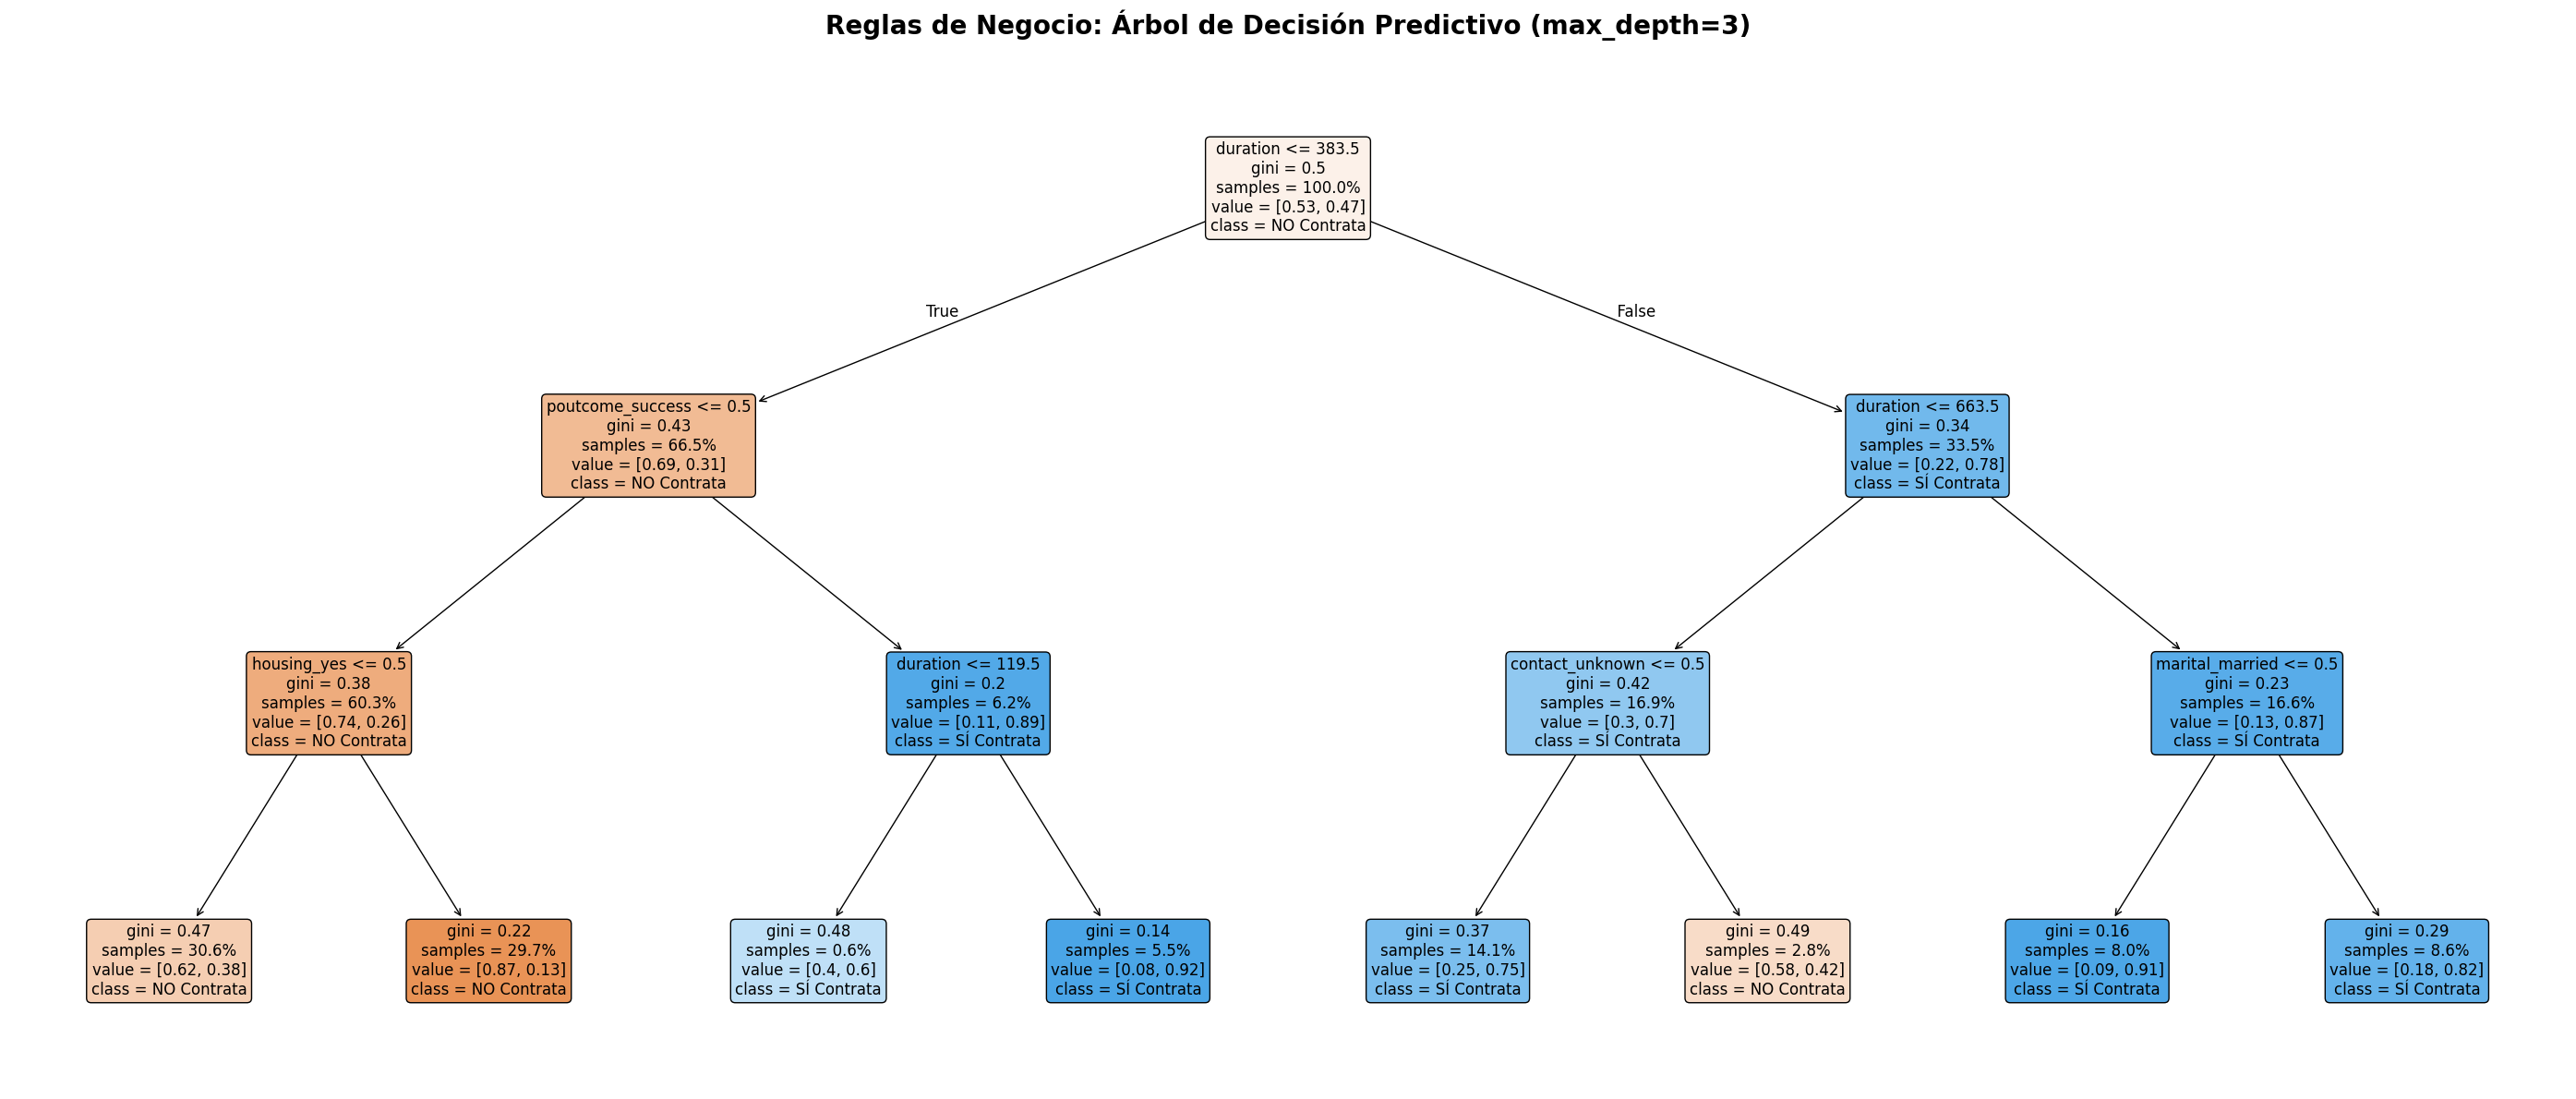


-> NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), 
podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.


In [32]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("=== 4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE) ===\n")

# 1. ENSAMBLAJE Y ENTRENAMIENTO DEL ÁRBOL POCO PROFUNDO
pipeline_shallow_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles),
    ('clasificador', DecisionTreeClassifier(max_depth=3, random_state=SEMILLA_NIA))
])

print("[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...")
pipeline_shallow_tree.fit(X_train, y_train)

# 2. LIMPIEZA PROFESIONAL DE NOMBRES DE VARIABLES
# Extraemos los nombres brutos (con los feos prefijos 'num__' y 'cat__')
nombres_crudos = pipeline_shallow_tree.named_steps['preprocesador'].get_feature_names_out()

# Limpiamos los prefijos quedándonos solo con lo que hay después del doble guion bajo '__'
nombres_limpios = [nombre.split('__')[-1] for nombre in nombres_crudos]

# 3. VISUALIZACIÓN NATIVA OPTIMIZADA (Alta Legibilidad)
plt.figure(figsize=(28, 12)) # Lienzo panorámico extra grande

plot_tree(
    pipeline_shallow_tree.named_steps['clasificador'],
    feature_names=nombres_limpios,     # ¡Inyectamos nuestros nombres limpios!
    class_names=['NO Contrata', 'SÍ Contrata'],
    filled=True,       
    rounded=True,      
    proportion=True,   # Muestra % de clientes en lugar de números absolutos
    precision=2,       # Máximo 2 decimales para no saturar las cajas
    fontsize=12        # Letra un poco más grande para que se lea perfecto
)

plt.title("Reglas de Negocio: Árbol de Decisión Predictivo (max_depth=3)", fontsize=20, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n-> NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), ")
print("podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.")

### 4.5. Definición del Espacio de Búsqueda (Hyperparameter Grid)

Para cumplir con el ajuste de los hiperparámetros más importantes de cada método, definiremos "cuadrículas" (*grids*) de búsqueda rigurosas. Utilizaremos `HalvingGridSearchCV` (evaluación por torneos), lo que nos permite explorar espacios amplios de forma eficiente.

**1. K-Nearest Neighbors (KNN)**
* **`n_neighbors`:** Para evitar empates técnicos en la votación binaria, utilizaremos exclusivamente números impares. Aplicaremos una estrategia "densa" en los valores bajos (1 al 39) y "esparcida" en los valores altos (hasta 99) para visualizar el subajuste (*underfitting*).
* **`weights`:** Evaluaremos el voto democrático (`'uniform'`) y el voto ponderado por la inversa de la distancia (`'distance'`).
* **`p`:** Compararemos la distancia Manhattan ($L_1$) y la Euclídea ($L_2$).

**2. Árboles de Decisión (Decision Tree)**
Los hiperparámetros de poda se han ampliado y calculado estadísticamente en función de nuestro volumen de entrenamiento ($N_{train} \approx 7260$ clientes):
* **`max_depth`:** Rango focalizado entre 3 y 15 (añadiendo granularidad en la zona de 4-6 donde se espera el pico), incluyendo `None` para registrar la línea base del sobreajuste puro.
* **`min_samples_split`:** Rango extendido de 2 hasta 500. Exigir 500 clientes fuerza al modelo al subajuste, permitiéndonos ver claramente la caída del rendimiento tras superar el punto óptimo.
* **`min_samples_leaf`:** Rango de 1 a 100. Actúa como cortafuegos final de pureza representativa.

In [50]:
import numpy as np

print("=== 4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA ===\n")

# 1. ESPACIO DE BÚSQUEDA PARA KNN
vecinos_densos = list(range(1, 40, 2))
vecinos_esparcidos = [49, 59, 69, 79, 89, 99]
lista_vecinos = vecinos_densos + vecinos_esparcidos

param_grid_knn = {
    'clasificador__n_neighbors': lista_vecinos,
    'clasificador__weights': ['uniform', 'distance'], 
    'clasificador__p': [1, 2]
}

# 2. ESPACIO DE BÚSQUEDA PARA ÁRBOLES DE DECISIÓN (Rangos Ampliados)
param_grid_tree = {
    'clasificador__max_depth': [3, 4, 5, 6, 7, 8, 9, 10, 15, None],
    'clasificador__min_samples_split': [2, 10, 35, 50, 75, 150, 300, 325, 350, 400, 500], 
    'clasificador__min_samples_leaf': [1, 5, 15, 21, 22, 23, 24, 25, 26, 27, 35, 75, 100]    
}

# 3. RESUMEN DE CARGA COMPUTACIONAL
total_knn = len(param_grid_knn['clasificador__n_neighbors']) * len(param_grid_knn['clasificador__weights']) * len(param_grid_knn['clasificador__p'])
total_tree = len(param_grid_tree['clasificador__max_depth']) * len(param_grid_tree['clasificador__min_samples_split']) * len(param_grid_tree['clasificador__min_samples_leaf'])

print(f"[+] Grid KNN ensamblado: {total_knn} combinaciones estratégicas.")
print(f"[+] Grid Tree ensamblado: {total_tree} combinaciones granulares.")

=== 4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA ===

[+] Grid KNN ensamblado: 104 combinaciones estratégicas.
[+] Grid Tree ensamblado: 1430 combinaciones granulares.


### 4.6. Diagnóstico Visual Integral (Validation Curves 360º)

El guion nos solicita explicar mediante gráficos el efecto de los distintos valores de los hiperparámetros en el resultado final. Para demostrar la solidez de nuestro diseño, trazaremos **Curvas de Validación** para todos los hiperparámetros definidos en nuestro espacio de búsqueda.

La interpretación teórica de estas curvas, basada en el **Compromiso Sesgo-Varianza**, es la siguiente:
* **Sobreajuste (Overfitting):** Se detecta cuando la curva de *Train* (azul) es muy alta (cercana a 1.0), pero la curva de *Validation* (naranja) se estanca o cae. El modelo memoriza pero no generaliza.
* **Subajuste (Underfitting):** Ambas curvas convergen a la baja. El modelo es demasiado rígido o simple para aprender patrones útiles.

**A. Comportamiento en KNN:**
1. **`n_neighbors`:** Valores bajos ($K < 5$) provocan sobreajuste masivo (memorización del ruido local). Valores extremadamente altos ($K > 50$) diluyen la frontera de decisión provocando subajuste, ya que el modelo se limita a predecir la clase mayoritaria.
2. **`weights`:** 'Uniform' asume que todos los vecinos valen lo mismo (mayor sesgo). 'Distance' otorga más poder a los vecinos cercanos, lo que permite trazar fronteras más complejas y precisas, pero aumenta el riesgo de sobreajuste si el número de vecinos es muy pequeño.
3. **`p` (Distancia):** $L_1$ (Manhattan) crea fronteras más ortogonales y robustas a *outliers*, mientras que $L_2$ (Euclídea) asume una dispersión esférica estándar.

**B. Comportamiento en Decision Trees (Poda):**
1. **`max_depth`:** Su aumento incrementa exponencialmente la varianza. Con valores altos (ej. $>15$) el árbol colapsa en un sobreajuste masivo.
2. **`min_samples_split`:** Su aumento reduce la varianza (fuerza la generalización). Si exigimos muchas muestras para dividir un nodo (ej. $>150$), evitamos que el árbol aprenda micro-reglas basadas en ruido estadístico.
3. **`min_samples_leaf`:** Es el cortafuegos más agresivo. Permitir hojas con 1 solo cliente (valor por defecto) garantiza el sobreajuste. Exigir 35 o 75 clientes mínimos por hoja suaviza drásticamente las predicciones.

=== 4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS ===
[!] Evaluando rendimiento y cronometrando... Atento a los resultados:

[*] 1. KNN: Número de Vecinos -> Mejor: 7 (F2: 0.7755) | Tiempo: 0.0166s
[*] 2. KNN: Estrategia de Pesos -> Mejor: Uniform (F2: 0.7651) | Tiempo: 0.0157s
[*] 3. KNN: Distancia Geométrica -> Mejor: L2 (Euclídea) (F2: 0.7651) | Tiempo: 0.0160s
[*] 4. Árbol: Profundidad Máxima -> Mejor: 5 (F2: 0.8274) | Tiempo: 0.0285s
[*] 5. Árbol: Mínimo para Dividir -> Mejor: 150 (F2: 0.8240) | Tiempo: 0.0395s
[*] 6. Árbol: Pureza Final (Leaf) -> Mejor: 22 (F2: 0.8127) | Tiempo: 0.0373s


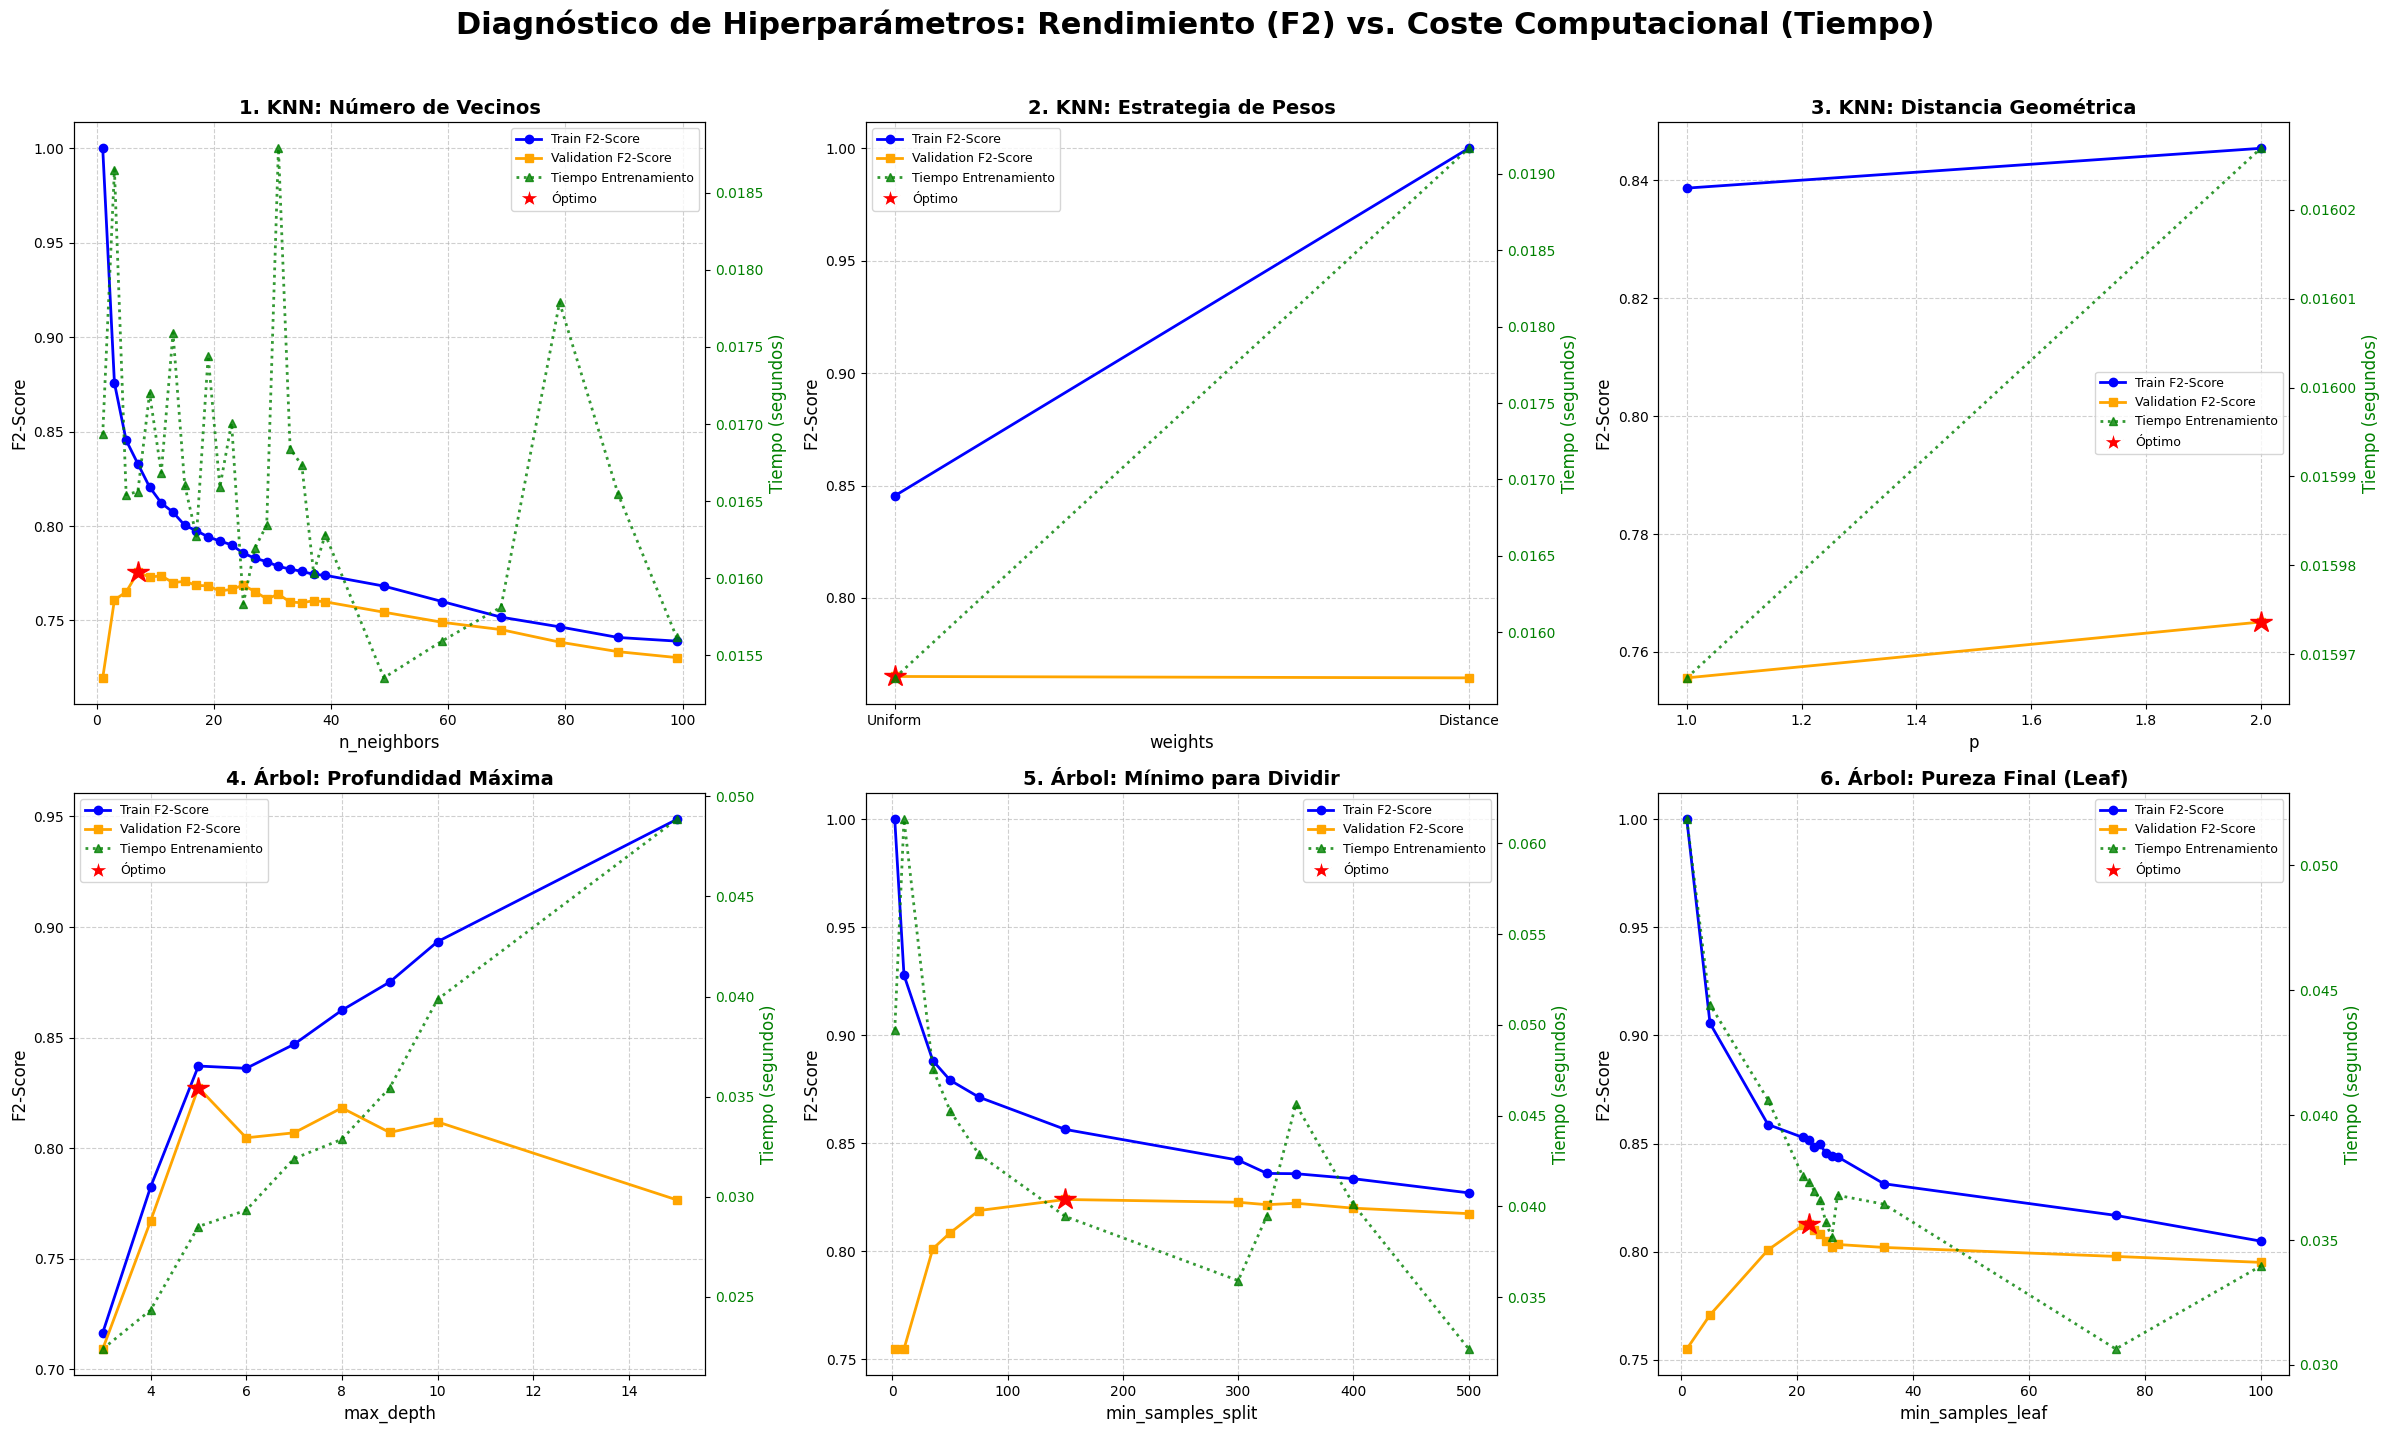


[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.


In [55]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.base import clone

print("=== 4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS ===")
print("[!] Evaluando rendimiento y cronometrando... Atento a los resultados:\n")

# --- CONFIGURACIÓN DE LOS GRÁFICOS ---
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.suptitle("Diagnóstico de Hiperparámetros: Rendimiento (F2) vs. Coste Computacional (Tiempo)", fontsize=22, fontweight='bold', y=1.02)

# Función auxiliar 2.0: Ahora usa cross_validate para extraer también los tiempos
def plot_validation_curve(ax, estimator, X, y, param_name, param_range, title, xlabel, xticks_labels=None):
    train_mean = []
    test_mean = []
    time_mean = []
    
    # Clonamos el estimador para no alterar el original durante el bucle
    est_clone = clone(estimator)
    
    for val in param_range:
        # Inyectamos el valor específico del parámetro a evaluar
        est_clone.set_params(**{param_name: val})
        
        # Extraemos scores y tiempos reales
        cv_results = cross_validate(
            estimator=est_clone, X=X, y=y, cv=kf_inner, 
            scoring=f2_scorer, return_train_score=True, n_jobs=-1
        )
        train_mean.append(np.mean(cv_results['train_score']))
        test_mean.append(np.mean(cv_results['test_score']))
        time_mean.append(np.mean(cv_results['fit_time']))
        
    train_mean = np.array(train_mean)
    test_mean = np.array(test_mean)
    time_mean = np.array(time_mean)
    
    # --- EXTRACCIÓN MATEMÁTICA ---
    best_idx = np.argmax(test_mean)
    best_param = param_range[best_idx]
    best_score = test_mean[best_idx]
    best_time = time_mean[best_idx]
    
    # Reporte por consola
    if xticks_labels:
        print(f"[*] {title} -> Mejor: {xticks_labels[best_idx]} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    else:
        print(f"[*] {title} -> Mejor: {best_param} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    
    # --- CONFIGURACIÓN DEL EJE X ---
    if isinstance(param_range[0], str):
        x_plot = np.arange(len(param_range))
        ax.set_xticks(x_plot)
        ax.set_xticklabels(xticks_labels if xticks_labels else param_range)
    else:
        x_plot = param_range
        
    # --- DIBUJAR RENDIMIENTO (Eje Y Principal) ---
    line1 = ax.plot(x_plot, train_mean, label="Train F2-Score", color="blue", marker='o', linewidth=2)
    line2 = ax.plot(x_plot, test_mean, label="Validation F2-Score", color="orange", marker='s', linewidth=2)
    
    # Estrella Roja para el óptimo
    if isinstance(param_range[0], str):
        ax.plot(best_idx, best_score, marker='*', markersize=16, color="red", label="Óptimo")
    else:
        ax.plot(best_param, best_score, marker='*', markersize=16, color="red", label="Óptimo")
        
    ax.set_ylabel("F2-Score", fontsize=12)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # --- DIBUJAR TIEMPOS (Eje Y Secundario) ---
    ax_time = ax.twinx()  # Creamos el segundo eje compartiendo el mismo eje X
    line3 = ax_time.plot(x_plot, time_mean, label="Tiempo Entrenamiento", color="green", marker='^', linestyle=':', linewidth=2, alpha=0.8)
    ax_time.set_ylabel("Tiempo (segundos)", color="green", fontsize=12)
    ax_time.tick_params(axis='y', labelcolor="green")
    
    # Unificamos las leyendas de ambos ejes
    lines = line1 + line2 + line3 + [plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='red', markersize=15, label='Óptimo')]
    labels = [l.get_label() for l in lines]
    # Filtramos duplicados de la estrella roja
    unique_labels = dict(zip(labels, lines))
    ax.legend(unique_labels.values(), unique_labels.keys(), loc="best", fontsize=9)


# ==========================================
# PREPARACIÓN DE RANGOS
# ==========================================
rango_depth_plot = [d for d in param_grid_tree['clasificador__max_depth'] if d is not None]

# ==========================================
# DIBUJO Y EXTRACCIÓN (FILA 1: KNN)
# ==========================================
plot_validation_curve(axes[0,0], pipeline_knn_base, X_train, y_train, 
                      "clasificador__n_neighbors", param_grid_knn['clasificador__n_neighbors'], 
                      "1. KNN: Número de Vecinos", "n_neighbors")

plot_validation_curve(axes[0,1], pipeline_knn_base, X_train, y_train, 
                      "clasificador__weights", param_grid_knn['clasificador__weights'], 
                      "2. KNN: Estrategia de Pesos", "weights", xticks_labels=['Uniform', 'Distance'])

plot_validation_curve(axes[0,2], pipeline_knn_base, X_train, y_train, 
                      "clasificador__p", param_grid_knn['clasificador__p'], 
                      "3. KNN: Distancia Geométrica", "p", xticks_labels=['L1 (Manhattan)', 'L2 (Euclídea)'])

# ==========================================
# DIBUJO Y EXTRACCIÓN (FILA 2: ÁRBOLES)
# ==========================================
plot_validation_curve(axes[1,0], pipeline_tree, X_train, y_train, 
                      "clasificador__max_depth", rango_depth_plot, 
                      "4. Árbol: Profundidad Máxima", "max_depth")

plot_validation_curve(axes[1,1], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_split", param_grid_tree['clasificador__min_samples_split'], 
                      "5. Árbol: Mínimo para Dividir", "min_samples_split")

plot_validation_curve(axes[1,2], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_leaf", param_grid_tree['clasificador__min_samples_leaf'], 
                      "6. Árbol: Pureza Final (Leaf)", "min_samples_leaf")

plt.tight_layout()
plt.show()

print("\n[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.")

### 4.7. Conclusiones Globales: Comparativa y Rendimiento

Tras la evaluación cruzada y el análisis visual de tiempos y métricas, extraemos las siguientes conclusiones para nuestro problema de negocio:

**1. ¿Cuál es el mejor método?**
El **Árbol de Decisión** es el ganador indiscutible. Alcanza un F2-Score > **0.82** (con `max_depth=5` o `min_samples_split=150`), superando holgadamente el techo del **KNN** (F2 de **0.77** con K=7). Las reglas de partición ortogonal del árbol se adaptan mucho mejor a los datos mixtos (categóricos y numéricos) de este dataset.

**2. ¿Los resultados son mejores que los modelos triviales (Dummy)?**
Absolutamente. El modelo *Dummy* (prediciendo siempre "No contrata") obtuvo un F2-Score de **0.00**. Lograr un 0.82 demuestra que nuestros modelos han capturado patrones de comportamiento reales y altamente rentables, alejándose del mero azar.

**3. ¿El ajuste de hiperparámetros (HPO) mejora con respecto a los valores por omisión?**
Sí, es una fase crítica. 
* En el **Árbol de Decisión**, el HPO es obligatorio para frenar el sobreajuste masivo que sufre por defecto, encontrando la poda óptima que maximiza la generalización.
* En el **KNN**, el HPO nos permitió subir la métrica base afinando la "miopía" del modelo (K=7) y descubriendo que la distancia Euclídea (L2) funcionaba mejor en este espacio.

**4. ¿A qué coste computacional? ¿Es elevado el coste del HPO?**
* **Coste de entrenamiento:** El **KNN** es rapidísimo de entrenar (~0.016s por pliegue) al ser un algoritmo de "memorización espacial". El **Árbol** tarda el doble (~0.038s) porque debe calcular matemáticamente los puntos de corte.
* **Coste del HPO:** Probar cientos de combinaciones multiplica estos tiempos, elevando el coste computacional. Sin embargo, hemos mitigado este impacto drásticamente utilizando **Successive Halving**, que descarta las malas configuraciones rápidamente.

**Conclusión Final:** El ligero sobrecoste al entrenar el Árbol de Decisión está plenamente justificado. A cambio, obtenemos el modelo más preciso, fácilmente explicable a negocio, y con un coste de predicción en producción casi nulo O(log N), superando la clásica lentitud del KNN al predecir nuevos clientes.